# Week 9 · Explore: a table, three charts and a live API

**Introduction to Computer Science (YMT113)** · Fall 2026

Nothing here is graded. This is the week 9 lecture as a notebook: run each cell (`Shift+Enter`), read the output,
change one thing, run it again. Everything is preinstalled in Colab.

## 1 · Get: write the data file

In a real job the file arrives by email or from a database. Here we create it, so that the notebook runs anywhere.

In [1]:
%%writefile scores.csv
name,section,lab2,lab3,lab4,lab5,lab6,lab7
Ada,A,10,9,8,10,10,10
Alan,A,9,10,7,8,2,9
Grace,A,10,10,10,10,10,10
Linus,A,6,7,5,0,0,3
Margaret,A,10,8,9,10,8,10
Dennis,A,8,9,10,9,10,10
Barbara,B,10,10,9,10,10,10
Ken,B,7,6,8,5,4,10
Katherine,B,10,10,10,9,10,10
Guido,B,5,8,6,7,2,10
Radia,B,9,9,10,10,10,9
Tim,B,0,4,6,0,0,0

Writing scores.csv


## 2 · Load and look

In [2]:
import pandas as pd

df = pd.read_csv("scores.csv")
df.head()

,name,section,lab2,lab3,lab4,lab5,lab6,lab7
0,Ada,A,10,9,8,10,10,10
1,Alan,A,9,10,7,8,2,9
2,Grace,A,10,10,10,10,10,10
3,Linus,A,6,7,5,0,0,3
4,Margaret,A,10,8,9,10,8,10


In [3]:
df.describe().round(2)

,lab2,lab3,lab4,lab5,lab6,lab7
count,12.00,12.00,12.00,12.00,12.00,12.00
mean,7.83,8.33,8.17,7.33,6.33,8.42
std,3.01,1.87,1.80,3.75,4.33,3.32
min,0.00,4.00,5.00,0.00,0.00,0.00
25%,6.75,7.75,6.75,6.50,2.00,9.00
50%,9.00,9.00,8.50,9.00,9.00,10.00
75%,10.00,10.00,10.00,10.00,10.00,10.00
max,10.00,10.00,10.00,10.00,10.00,10.00


## 3 · Ask questions

Change the condition and run again: who scored 10 on every lab from 5 to 7? Who is in section B and below 5 on Lab 6?

In [4]:
df[df["lab6"] < 5]

,name,section,lab2,lab3,lab4,lab5,lab6,lab7
1,Alan,A,9,10,7,8,2,9
3,Linus,A,6,7,5,0,0,3
7,Ken,B,7,6,8,5,4,10
9,Guido,B,5,8,6,7,2,10
11,Tim,B,0,4,6,0,0,0


In [5]:
labs = ["lab2", "lab3", "lab4", "lab5", "lab6", "lab7"]
df["total"] = df[labs].sum(axis=1)
df["missing"] = (df[labs] == 0).sum(axis=1)
df.sort_values("total", ascending=False)[["name", "section", "total", "missing"]]

,name,section,total,missing
2,Grace,A,60,0
6,Barbara,B,59,0
8,Katherine,B,59,0
0,Ada,A,57,0
10,Radia,B,57,0
5,Dennis,A,56,0
4,Margaret,A,55,0
1,Alan,A,45,0
7,Ken,B,40,0
9,Guido,B,38,0


In [6]:
df.groupby("section")[labs].mean().round(2)

,lab2,lab3,lab4,lab5,lab6,lab7
section,,,,,,
A,8.83,8.83,8.17,7.83,6.67,8.67
B,6.83,7.83,8.17,6.83,6.00,8.17


## 4 · Show

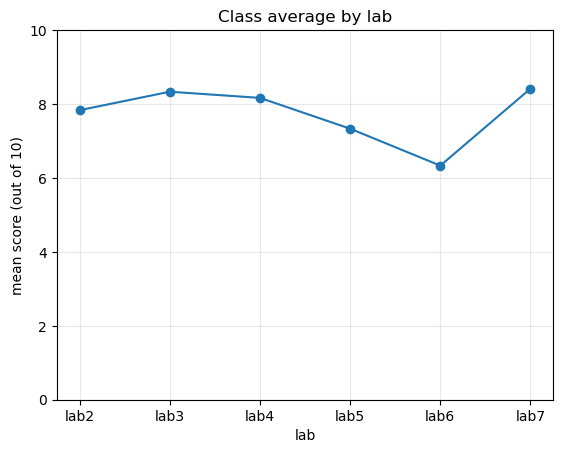

In [7]:
import matplotlib.pyplot as plt

means = df[labs].mean()
plt.plot(labs, means, marker="o")
plt.title("Class average by lab"); plt.xlabel("lab"); plt.ylabel("mean score (out of 10)")
plt.ylim(0, 10); plt.grid(alpha=0.3)
plt.show()

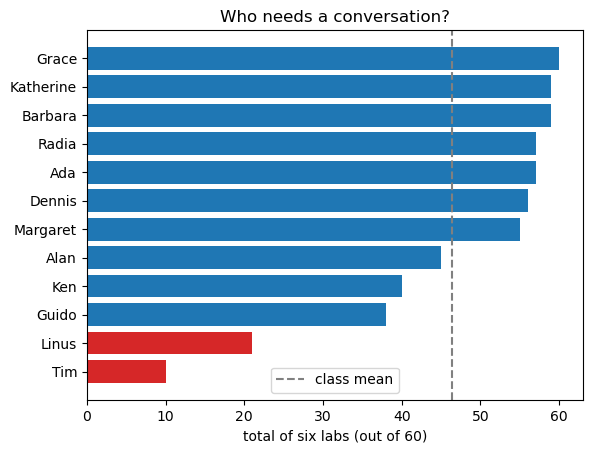

In [8]:
ordered = df.sort_values("total")
colors = ["tab:red" if t < 30 else "tab:blue" for t in ordered["total"]]
plt.barh(ordered["name"], ordered["total"], color=colors)
plt.axvline(df["total"].mean(), linestyle="--", color="gray", label="class mean")
plt.xlabel("total of six labs (out of 60)"); plt.title("Who needs a conversation?"); plt.legend()
plt.show()

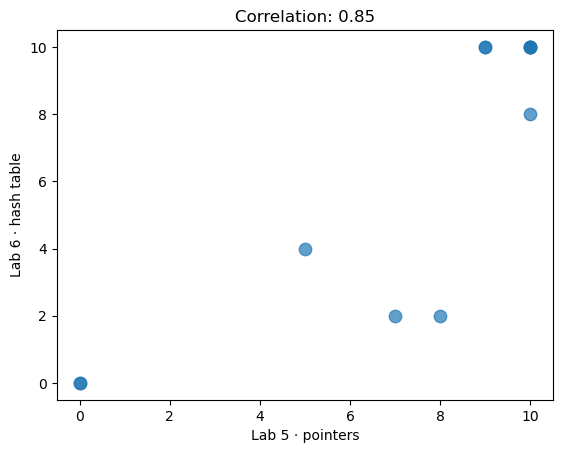

In [9]:
plt.scatter(df["lab5"], df["lab6"], s=80, alpha=0.7)
plt.xlabel("Lab 5 · pointers"); plt.ylabel("Lab 6 · hash table")
plt.title(f"Correlation: {df['lab5'].corr(df['lab6']):.2f}")
plt.show()

## 5 · Live data from a web API

Open-Meteo needs no key. The cell asks for three days of hourly temperature for Elazığ, makes a table and draws it.
Change the latitude and longitude to your home town.

In [10]:
import requests

params = {"latitude": 38.67, "longitude": 39.22, "hourly": "temperature_2m", "forecast_days": 3, "timezone": "Europe/Istanbul"}
response = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=10)
print(response.status_code)

weather = pd.DataFrame(response.json()["hourly"])
weather["time"] = pd.to_datetime(weather["time"])
weather.head()

200


,time,temperature_2m
0,2026-11-16 00:00:00,9.2
1,2026-11-16 01:00:00,8.8
2,2026-11-16 02:00:00,8.6
3,2026-11-16 03:00:00,8.3
4,2026-11-16 04:00:00,7.9


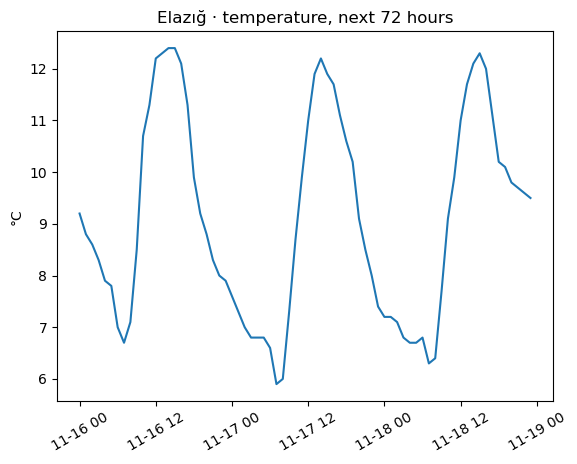

In [11]:
plt.plot(weather["time"], weather["temperature_2m"])
plt.title("Elazığ · temperature, next 72 hours"); plt.ylabel("°C"); plt.xticks(rotation=30)
plt.show()

## 6 · Your turn

1. Add a column `improved` that is `True` when `lab7` is greater than `lab6`. How many students improved? (`df["improved"].sum()`)
2. Draw a histogram of the totals: `plt.hist(df["total"], bins=6)`. What does its shape tell you about the class?
3. Ask the API for `wind_speed_10m` as well (`"hourly": "temperature_2m,wind_speed_10m"`) and plot both. Do they move together?
4. Find one free API in the [public-apis list](https://github.com/public-apis/public-apis) that could feed your semester project, and make one request to it.